**Author:** Li You  

This code file performs the textual analysis. AI tools were used only for revision and improvement of code quality.

In [19]:
# This cell fits predictive models using text features (if a target exists).
!pip install spacy textblob lightgbm shap
!python -m spacy download en_core_web_sm

   ---------------------------------------- 0.0/14.2 MB ? eta -:--:--
    --------------------------------------- 0.3/14.2 MB ? eta -:--:--
   -- ------------------------------------- 0.8/14.2 MB 2.2 MB/s eta 0:00:07
   -- ------------------------------------- 0.8/14.2 MB 2.2 MB/s eta 0:00:07
   -- ------------------------------------- 1.0/14.2 MB 1.3 MB/s eta 0:00:11
   ----- ---------------------------------- 1.8/14.2 MB 1.8 MB/s eta 0:00:07
   ------- -------------------------------- 2.6/14.2 MB 2.2 MB/s eta 0:00:06
   --------- ------------------------------ 3.4/14.2 MB 2.4 MB/s eta 0:00:05
   ---------- ----------------------------- 3.7/14.2 MB 2.4 MB/s eta 0:00:05
   ------------ --------------------------- 4.5/14.2 MB 2.5 MB/s eta 0:00:04
   -------------- ------------------------- 5.0/14.2 MB 2.5 MB/s eta 0:00:04
   -------------- ------------------------- 5.2/14.2 MB 2.4 MB/s eta 0:00:04
   ---------------- ----------------------- 5.8/14.2 MB 2.4 MB/s eta 0:00:04
   ----------

In [20]:
# This cell imports libraries and sets up dependencies.
import os
import re
import json
import math
import warnings
from collections import Counter, defaultdict
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import TruncatedSVD, PCA, LatentDirichletAllocation
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

import statsmodels.api as sm

OPTIONAL = {}
for name, module in [
    ("nltk", "nltk"),
    ("spacy", "spacy"),
    ("textblob", "textblob"),
    ("lightgbm", "lightgbm"),
    ("shap", "shap"),
]:
    try:
        OPTIONAL[name] = __import__(module)
    except Exception:
        OPTIONAL[name] = None

print({k: v is not None for k, v in OPTIONAL.items()})

{'nltk': True, 'spacy': True, 'textblob': True, 'lightgbm': True, 'shap': True}


In [2]:
# This cell defines file paths and loads the input dataset.
CSV_PATH = r"C:\Users\16172\OneDrive\桌面\RA\Music&Finance\lyrics_batches_covered_Li\covered_Li_with_lyrics_progress.csv"

encodings_to_try = ["utf-8", "utf-8-sig", "gbk", "latin1"]
df_raw = None
last_err = None
for enc in encodings_to_try:
    try:
        df_raw = pd.read_csv(CSV_PATH, encoding=enc, low_memory=False)
        print(f"Loaded with encoding={enc}, shape={df_raw.shape}")
        break
    except Exception as e:
        last_err = e

if df_raw is None:
    raise RuntimeError(f"Failed to load CSV. Last error: {last_err}")

df_raw = df_raw.loc[:, ~df_raw.columns.astype(str).str.contains(r"^Unnamed", case=False, regex=True)]

orig_cols = list(df_raw.columns)
df = df_raw.copy()
df.columns = [str(c).strip() for c in df.columns]

print("Columns:", df.columns.tolist()[:100])

Loaded with encoding=utf-8, shape=(69948, 9)
Columns: ['uri', 'artist_name', 'track_name', 'source', 'azlyrics_url', 'lyrics', 'lyrics_status', 'lyrics_fetch_method', 'lyrics_error']


In [3]:
# This cell auto-detects key columns (lyrics, status, metadata fields).
def find_col(candidates, cols):
    lower_map = {c.lower(): c for c in cols}
    for cand in candidates:
        if cand.lower() in lower_map:
            return lower_map[cand.lower()]
    for c in cols:
        lc = c.lower()
        for cand in candidates:
            if cand.lower() in lc:
                return c
    return None

cols = df.columns.tolist()

LYRICS_COL = find_col(["lyrics", "lyric"], cols)
STATUS_COL = find_col(["lyrics_status", "status"], cols)

TRACK_COL  = find_col(["track_name", "song_name", "song", "track", "title"], cols)
ARTIST_COL = find_col(["artist_name", "artist"], cols)
DATE_COL   = find_col(["date", "chart_date", "snapshot_date", "week", "day"], cols)
RANK_COL   = find_col(["rank", "chart_rank", "position"], cols)
COUNTRY_COL= find_col(["country", "market", "region"], cols)
SPOTIFY_ID_COL = find_col(["track_id", "spotify_track_id", "id"], cols)

print("Detected columns:")
for k, v in [
    ("LYRICS_COL", LYRICS_COL), ("STATUS_COL", STATUS_COL), ("TRACK_COL", TRACK_COL),
    ("ARTIST_COL", ARTIST_COL), ("DATE_COL", DATE_COL), ("RANK_COL", RANK_COL),
    ("COUNTRY_COL", COUNTRY_COL), ("SPOTIFY_ID_COL", SPOTIFY_ID_COL)
]:
    print(f"  {k}: {v}")

if LYRICS_COL is None:
    raise ValueError("Could not detect lyrics column. Please manually set LYRICS_COL.")

Detected columns:
  LYRICS_COL: lyrics
  STATUS_COL: lyrics_status
  TRACK_COL: track_name
  ARTIST_COL: artist_name
  DATE_COL: None
  RANK_COL: None
  COUNTRY_COL: None
  SPOTIFY_ID_COL: None


In [4]:
# This cell auto-detects key columns (lyrics, status, metadata fields).
work = df.copy()

if STATUS_COL is not None:
    work = work[work[STATUS_COL].astype(str).str.lower().eq("ok")].copy()

work = work[work[LYRICS_COL].notna()].copy()
work[LYRICS_COL] = work[LYRICS_COL].astype(str)

def basic_clean_lyrics(text):
    t = str(text)
    t = t.replace("\r", " ").replace("\n", " ")
    t = re.sub(r"\[[^\]]+\]", " ", t)  # remove [Chorus], [Verse]
    t = re.sub(r"\([^\)]*\)", lambda m: " " if len(m.group(0)) < 40 else m.group(0), t)
    t = re.sub(r"[^A-Za-z'\-\s]", " ", t)  # keep alpha/space/apostrophe/hyphen
    t = re.sub(r"\s+", " ", t).strip().lower()
    return t

work["lyrics_clean"] = work[LYRICS_COL].map(basic_clean_lyrics)
work = work[work["lyrics_clean"].str.len() > 0].copy()

if DATE_COL is not None:
    work["_date"] = pd.to_datetime(work[DATE_COL], errors="coerce")
else:
    work["_date"] = pd.NaT

if RANK_COL is not None:
    work["_rank"] = pd.to_numeric(work[RANK_COL], errors="coerce")
else:
    work["_rank"] = np.nan

print("Filtered shape:", work.shape)
work[[c for c in [TRACK_COL, ARTIST_COL, COUNTRY_COL, DATE_COL, RANK_COL, LYRICS_COL, "lyrics_clean"] if c is not None][:8]].head(3)

Filtered shape: (10296, 12)


,track_name,artist_name,lyrics,lyrics_clean
0,Airforce,"Bausa, FAST BOY",When she put her Air Force on\nShe the only on...,when she put her air force on she the only one...
2,Leben (Tod),"Kolja Goldstein, D煤 Maroc",[Kolja Goldstein:]\nAh-ahh\nWir entkomm'n dem ...,ah-ahh wir entkomm'n dem tod nicht wir leben m...
4,Liebe & Hass,Symba,Ich sag zu meinem Homie ich werd nicht verhaft...,ich sag zu meinem homie ich werd nicht verhaft...


In [5]:
# This cell imports libraries and sets up dependencies.
try:
    import nltk
    from nltk.corpus import stopwords
    from nltk.tokenize import word_tokenize
    from nltk.stem import WordNetLemmatizer
    _ = stopwords.words("english")
    NLTK_READY = True
except Exception:
    NLTK_READY = False

CUSTOM_LYRIC_STOPWORDS = {
    "oh","ooh","oooh","ah","aah","uh","la","na","nah","yeah","ya","yo","hey","woo","woah","whoa",
    "im","ive","youre","dont","cant","wont","aint","ill","id","thats","theres","didnt","isnt"
}
STOPWORDS = set(ENGLISH_STOP_WORDS).union(CUSTOM_LYRIC_STOPWORDS)

lemmatizer = WordNetLemmatizer() if NLTK_READY else None

def tokenize(text, lemmatize=True):
    text = str(text).lower()
    toks = re.findall(r"[a-zA-Z]+(?:'[a-zA-Z]+)?", text)
    toks = [t for t in toks if t not in STOPWORDS and len(t) > 1]
    if lemmatize and lemmatizer is not None:
        toks = [lemmatizer.lemmatize(t) for t in toks]
    return toks

work["tokens"] = work["lyrics_clean"].map(tokenize)
work["n_tokens"] = work["tokens"].map(len)
work = work[work["n_tokens"] > 2].copy()
work["type_token_ratio"] = work["tokens"].map(lambda x: len(set(x))/len(x) if len(x)>0 else np.nan)
work["avg_token_len"] = work["tokens"].map(lambda x: np.mean([len(t) for t in x]) if len(x)>0 else np.nan)

print(work[["n_tokens","type_token_ratio","avg_token_len"]].describe().T)

                    count        mean         std       min         25%  \
n_tokens          10293.0  346.237346  149.954257  4.000000  256.000000   
type_token_ratio  10293.0    0.465467    0.110214  0.056180    0.390777   
avg_token_len     10293.0    4.546685    0.363387  2.961415    4.322330   

                         50%         75%          max  
n_tokens          341.000000  425.000000  3975.000000  
type_token_ratio    0.460784    0.533186     1.000000  
avg_token_len       4.517391    4.737557     7.869565  


In [22]:
# This cell imports libraries and sets up dependencies.
POS_WORDS = {"love","happy","joy","smile","sunshine","beautiful","free","dream","light","heaven","dance"}
NEG_WORDS = {"pain","hurt","cry","alone","dark","broken","fear","blood","die","death","tears","sad"}

PRONOUNS_1 = {"i","me","my","mine","myself","we","us","our","ours"}
PRONOUNS_2 = {"you","your","yours","yourself","yourselves"}
PRONOUNS_3 = {"he","him","his","she","her","hers","they","them","their","theirs"}

def line_stats(raw):
    lines = [ln.strip() for ln in str(raw).splitlines() if ln.strip()]
    if not lines:
        return pd.Series({"n_lines": np.nan, "avg_line_len_chars": np.nan, "repetition_ratio_lines": np.nan})
    lc = [re.sub(r"\s+"," ",l.lower()) for l in lines]
    counts = Counter(lc)
    repeated = sum(v for v in counts.values() if v>1)
    return pd.Series({
        "n_lines": len(lines),
        "avg_line_len_chars": np.mean([len(l) for l in lines]),
        "repetition_ratio_lines": repeated / len(lines)
    })

def token_based_features(toks):
    if len(toks)==0:
        return pd.Series(dtype=float)
    c = Counter(toks)
    total = len(toks)
    pos = sum(c[w] for w in POS_WORDS)
    neg = sum(c[w] for w in NEG_WORDS)
    uniq = len(c)
    hapax = sum(1 for _,v in c.items() if v==1)
    first = sum(c[w] for w in PRONOUNS_1)
    second = sum(c[w] for w in PRONOUNS_2)
    third = sum(c[w] for w in PRONOUNS_3)
    return pd.Series({
        "lexical_diversity_ttr": uniq/total,
        "hapax_ratio": hapax/total,
        "pos_lexicon_rate": pos/total,
        "neg_lexicon_rate": neg/total,
        "sent_lexicon_balance": (pos-neg)/total,
        "pron_1_rate": first/total,
        "pron_2_rate": second/total,
        "pron_3_rate": third/total,
        "repetition_top1_rate": c.most_common(1)[0][1]/total,
        "repetition_top5_share": sum(v for _,v in c.most_common(5))/total
    })

feat_lines = work[LYRICS_COL].map(line_stats)
feat_toks = work["tokens"].map(token_based_features)

work = pd.concat([work.reset_index(drop=True), feat_lines.reset_index(drop=True), feat_toks.reset_index(drop=True)], axis=1)

if OPTIONAL["textblob"] is not None:
    from textblob import TextBlob
    work["tb_polarity"] = work["lyrics_clean"].map(lambda t: TextBlob(t[:5000]).sentiment.polarity if isinstance(t,str) else np.nan)
    work["tb_subjectivity"] = work["lyrics_clean"].map(lambda t: TextBlob(t[:5000]).sentiment.subjectivity if isinstance(t,str) else np.nan)
else:
    work["tb_polarity"] = np.nan
    work["tb_subjectivity"] = np.nan

work.head(2)

,uri,artist_name,track_name,source,azlyrics_url,lyrics,lyrics_status,lyrics_fetch_method,lyrics_error,lyrics_clean,...,lda_topic_12,lda_topic_13,lda_topic_14,lda_topic_15,pc1_text,pc2_text,lyrics,lyrics,tokens,tokens
0,spotify:track:52DjIXARE3qh096lgv77XA,"Bausa, FAST BOY",Airforce,BAUSA / Warner Music Central Europe,https://www.azlyrics.com/lyrics/bausa/airforce...,When she put her Air Force on\nShe the only on...,ok,NaN,NaN,when she put her air force on she the only one...,...,0.266843,0.000252,0.059525,0.322786,-0.985688,-0.084207,n_lines 59.000000 avg_line_l...,n_lines 4.00 avg_line_len_c...,lexical_diversity_ttr 0.353791 hapax_ratio ...,lexical_diversity_ttr 0.7 hapax_ratio ...
1,spotify:track:16xSUVErzwnAqR7Wd759Kd,"Kolja Goldstein, D煤 Maroc",Leben (Tod),Chapter One,https://www.azlyrics.com/lyrics/koljagoldstein...,[Kolja Goldstein:]\nAh-ahh\nWir entkomm'n dem ...,ok,NaN,NaN,ah-ahh wir entkomm'n dem tod nicht wir leben m...,...,0.123797,0.000225,0.692039,0.168023,-1.136257,-1.235154,n_lines 54.000000 avg_line_l...,n_lines 4.00 avg_line_len_c...,lexical_diversity_ttr 0.483607 hapax_ratio ...,lexical_diversity_ttr 0.8 hapax_ratio ...


In [23]:
# This cell tries to detect a numeric target and creates grouping buckets.
def detect_numeric_targets(df_):
    nums = []
    for c in df_.columns:
        if c.startswith("_"): 
            continue
        if pd.api.types.is_numeric_dtype(df_[c]):
            miss = df_[c].isna().mean()
            nunq = df_[c].nunique(dropna=True)
            if miss < 0.95 and nunq > 10:
                nums.append(c)
    return nums

numeric_targets = detect_numeric_targets(work)
print("Candidate numeric columns:", numeric_targets[:50])

score_candidates = [c for c in work.columns if any(k in c.lower() for k in ["score", "rating", "attractiveness", "sentiment_ai", "ai_score"])]
TARGET_COL = score_candidates[0] if score_candidates else None

if TARGET_COL is None and "_rank" in work.columns and work["_rank"].notna().sum() > 20:
    work["target_from_rank"] = -work["_rank"]  # rank 1 should be high target
    TARGET_COL = "target_from_rank"

print("TARGET_COL =", TARGET_COL)

if TARGET_COL is not None and work[TARGET_COL].notna().sum() > 30:
    x = work[TARGET_COL]
    q20, q80 = x.quantile([0.2, 0.8])
    def bucket(v):
        if pd.isna(v): return np.nan
        if v >= q80: return "Top20"
        if v <= q20: return "Bottom20"
        return "Avg"
    work["target_bucket"] = x.map(bucket)
else:
    work["target_bucket"] = np.nan

print(work["target_bucket"].value_counts(dropna=False))

Candidate numeric columns: ['n_tokens', 'type_token_ratio', 'avg_token_len', 'tb_polarity', 'tb_subjectivity', 'lda_topic_00', 'lda_topic_01', 'lda_topic_02', 'lda_topic_03', 'lda_topic_04', 'lda_topic_05', 'lda_topic_06', 'lda_topic_07', 'lda_topic_08', 'lda_topic_09', 'lda_topic_10', 'lda_topic_11', 'lda_topic_12', 'lda_topic_13', 'lda_topic_14', 'lda_topic_15', 'pc1_text', 'pc2_text']
TARGET_COL = None
target_bucket
NaN    10293
Name: count, dtype: int64


In [24]:
# This cell tries to detect a numeric target and creates grouping buckets.
feature_cols_basic = [
    "n_tokens","type_token_ratio","avg_token_len","n_lines","avg_line_len_chars","repetition_ratio_lines",
    "lexical_diversity_ttr","hapax_ratio","pos_lexicon_rate","neg_lexicon_rate","sent_lexicon_balance",
    "pron_1_rate","pron_2_rate","pron_3_rate","repetition_top1_rate","repetition_top5_share",
    "tb_polarity","tb_subjectivity"
]
feature_cols_basic = [c for c in feature_cols_basic if c in work.columns]

corr_target = TARGET_COL
if corr_target is not None:
    corr_tbl = []
    for c in feature_cols_basic:
        tmp = work[[c, corr_target]].dropna()
        if len(tmp) < 20:
            continue
        corr_tbl.append({
            "feature": c,
            "pearson_corr": tmp[c].corr(tmp[corr_target]),
            "spearman_corr": tmp[c].rank().corr(tmp[corr_target].rank()),
            "n": len(tmp)
        })
    corr_df = pd.DataFrame(corr_tbl).sort_values("abs_pearson", ascending=False) if corr_tbl else pd.DataFrame()

    if not corr_df.empty:
        corr_df["abs_pearson"] = corr_df["pearson_corr"].abs()
        corr_df = corr_df.sort_values("abs_pearson", ascending=False)
        display(corr_df.head(20))

        plt.figure(figsize=(8,5))
        show = corr_df.head(15).iloc[::-1]
        plt.barh(show["feature"], show["pearson_corr"])
        plt.axvline(0, linestyle="--")
        plt.title("Cross-sectional correlation with target (lyrics features)")
        plt.xlabel("Pearson correlation")
        plt.show()
    else:
        print("Not enough data to compute cross-sectional correlations.")
else:
    print("No target column detected; skip target-based correlation. You can still inspect distributions below.")

No target column detected; skip target-based correlation. You can still inspect distributions below.


In [25]:
# This cell filters valid rows and cleans raw lyrics text.
def build_tfidf_matrix(texts, max_features=5000, ngram_range=(1,2), min_df=5, max_df=0.8):
    vect = TfidfVectorizer(
        max_features=max_features,
        ngram_range=ngram_range,
        min_df=min_df,
        max_df=max_df,
        stop_words=list(STOPWORDS),
        token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b"
    )
    X = vect.fit_transform(texts)
    terms = np.array(vect.get_feature_names_out())
    return vect, X, terms

if "target_bucket" in work.columns and work["target_bucket"].notna().sum() > 50:
    sub = work[work["target_bucket"].isin(["Top20","Avg","Bottom20"])].copy()
    vect_tfidf, X_tfidf, terms = build_tfidf_matrix(sub["lyrics_clean"], max_features=5000, min_df=5)
    sub = sub.reset_index(drop=True)

    def mean_tfidf_for(group_name):
        idx = sub.index[sub["target_bucket"].eq(group_name)].tolist()
        if len(idx)==0:
            return None
        return np.asarray(X_tfidf[idx].mean(axis=0)).ravel()

    m_top = mean_tfidf_for("Top20")
    m_avg = mean_tfidf_for("Avg")
    m_bot = mean_tfidf_for("Bottom20")

    tfidf_cmp = pd.DataFrame({"term": terms})
    if m_top is not None: tfidf_cmp["Top20"] = m_top
    if m_avg is not None: tfidf_cmp["Avg"] = m_avg
    if m_bot is not None: tfidf_cmp["Bottom20"] = m_bot

    if {"Top20","Avg"}.issubset(tfidf_cmp.columns):
        tfidf_cmp["Top_minus_Avg"] = tfidf_cmp["Top20"] - tfidf_cmp["Avg"]
    if {"Bottom20","Avg"}.issubset(tfidf_cmp.columns):
        tfidf_cmp["Bottom_minus_Avg"] = tfidf_cmp["Bottom20"] - tfidf_cmp["Avg"]
    if {"Top20","Bottom20"}.issubset(tfidf_cmp.columns):
        tfidf_cmp["Top_minus_Bottom"] = tfidf_cmp["Top20"] - tfidf_cmp["Bottom20"]

    display(tfidf_cmp.sort_values("Top_minus_Avg", ascending=False).head(20) if "Top_minus_Avg" in tfidf_cmp else tfidf_cmp.head())
    display(tfidf_cmp.sort_values("Top_minus_Avg", ascending=True).head(20) if "Top_minus_Avg" in tfidf_cmp else tfidf_cmp.head())
else:
    print("No target buckets available; skip group TF-IDF comparison.")

No target buckets available; skip group TF-IDF comparison.


In [28]:
# This cell imports libraries and sets up dependencies.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation, TruncatedSVD
from sklearn.cluster import KMeans

def safe_display(df_, n=20, sort_by=None, ascending=False, title=None):
    if title:
        print(title)
    if df_ is None or len(df_) == 0:
        print("(empty)")
        return
    tmp = df_.copy()
    if sort_by is not None and sort_by in tmp.columns:
        tmp = tmp.sort_values(sort_by, ascending=ascending)
    display(tmp.head(n))

def build_tfidf_matrix(
    texts, 
    max_features=5000, 
    ngram_range=(1,2), 
    min_df=5, 
    max_df=0.8,
    stopwords=None
):
    vec = TfidfVectorizer(
        max_features=max_features,
        ngram_range=ngram_range,
        min_df=min_df,
        max_df=max_df,
        stop_words=list(stopwords) if stopwords is not None else None,
        token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b"
    )
    X = vec.fit_transform(texts)
    terms = np.array(vec.get_feature_names_out())
    return vec, X, terms

def top_terms_from_vector(values, terms, topn=20):
    """values: 1d array-like"""
    values = np.asarray(values).ravel()
    idx = np.argsort(-values)[:topn]
    return pd.DataFrame({"term": terms[idx], "score": values[idx]})

def tfidf_mean_by_group(X, group_series, group_name):
    idx = np.where(group_series.values == group_name)[0]
    if len(idx) == 0:
        return None
    return np.asarray(X[idx].mean(axis=0)).ravel()

def plot_barh_terms(df_terms, value_col="score", term_col="term", title="", topn=15):
    if df_terms is None or df_terms.empty:
        print("(no data to plot)")
        return
    show = df_terms.head(topn).iloc[::-1]
    plt.figure(figsize=(8, max(4, topn*0.28)))
    plt.barh(show[term_col], show[value_col])
    plt.title(title)
    plt.tight_layout()
    plt.show()

Global TF-IDF (top terms/bigrams by mean TF-IDF)


,term,mean_tfidf
1850,ich,0.065707
3294,pas,0.053536
2474,le,0.048955
2537,les,0.048082
809,dans,0.038182
429,c'est,0.034341
1106,du,0.032777
4529,tu,0.032674
2208,je,0.032080
4582,und,0.031972


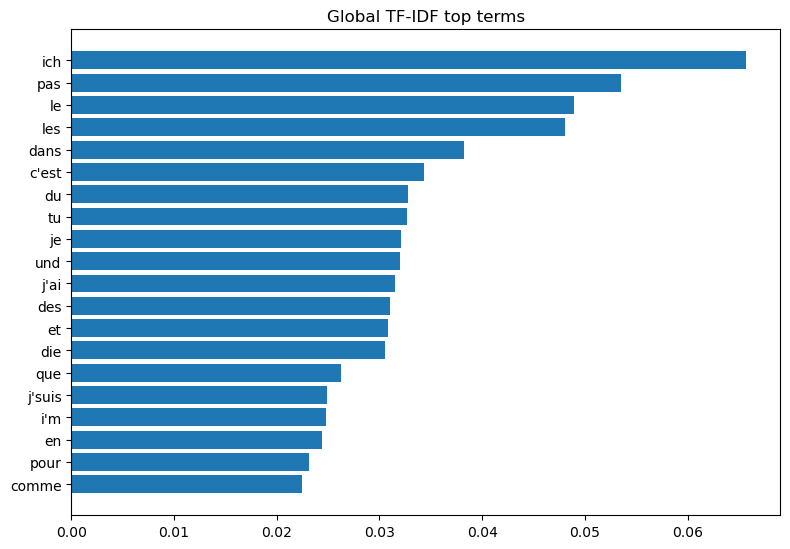

In [30]:
# This cell filters valid rows and cleans raw lyrics text.
texts_all = work["lyrics_clean"].fillna("").astype(str)
texts_all = texts_all[texts_all.str.len() > 0]

vec_global, X_global, terms_global = build_tfidf_matrix(
    texts_all,
    max_features=5000,
    ngram_range=(1,2),
    min_df=5,
    max_df=0.8,
    stopwords=STOPWORDS
)

mean_tfidf_global = np.asarray(X_global.mean(axis=0)).ravel()
tfidf_global_df = pd.DataFrame({
    "term": terms_global,
    "mean_tfidf": mean_tfidf_global
}).sort_values("mean_tfidf", ascending=False)

safe_display(tfidf_global_df, n=30, title="Global TF-IDF (top terms/bigrams by mean TF-IDF)")
plot_barh_terms(tfidf_global_df, value_col="mean_tfidf", title="Global TF-IDF top terms", topn=20)

Eligible artists (n>=20): 107
Showing: ['Jul', 'Djadja & Dinaz', 'Morgan Wallen', 'Vald', 'Naps', 'RK', 'Luciano', 'PLK', 'Kaaris', 'Josman', 'Niro', 'Timal']


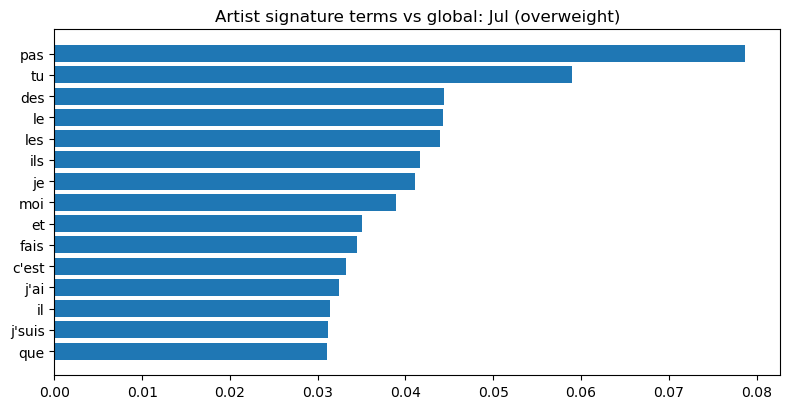

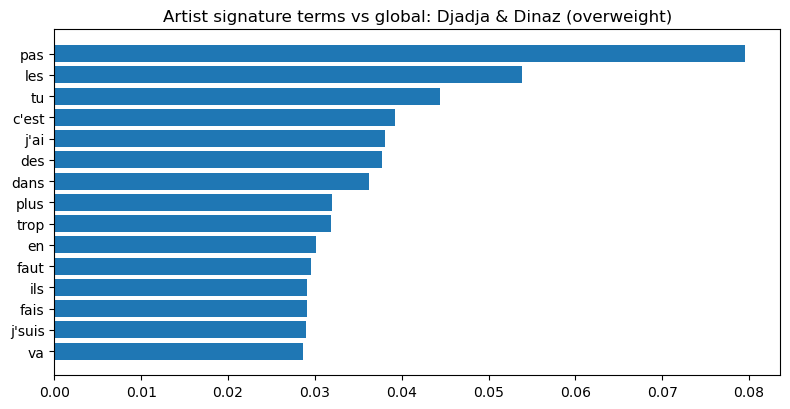

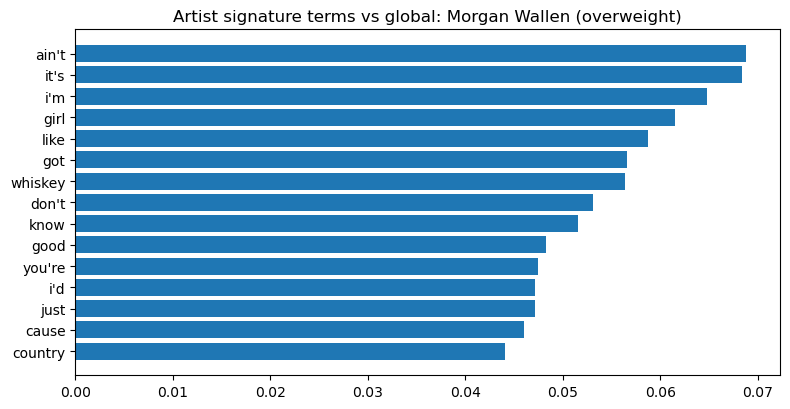

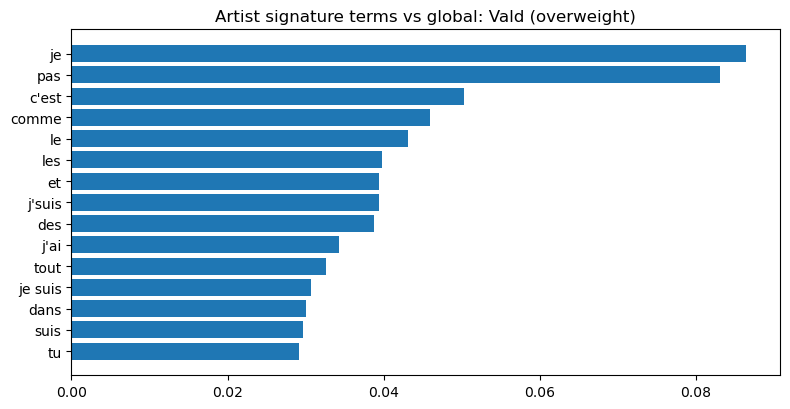

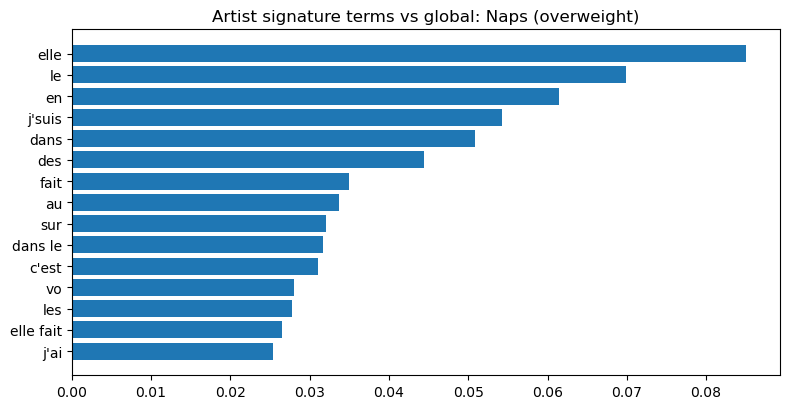

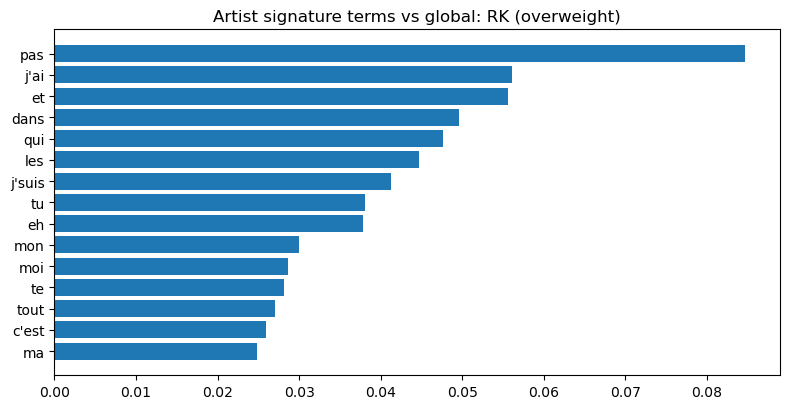

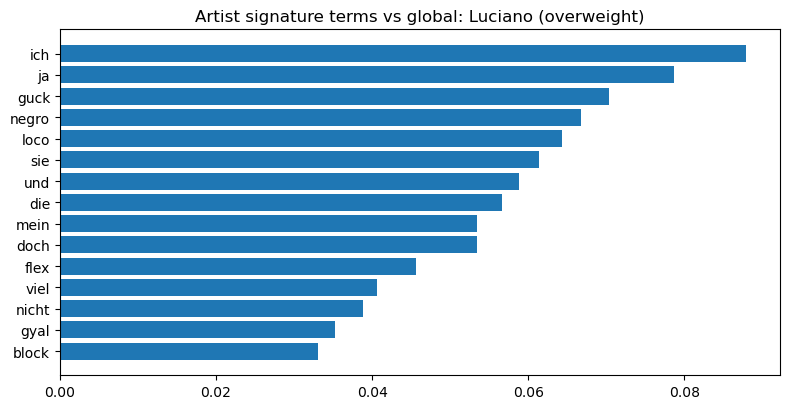

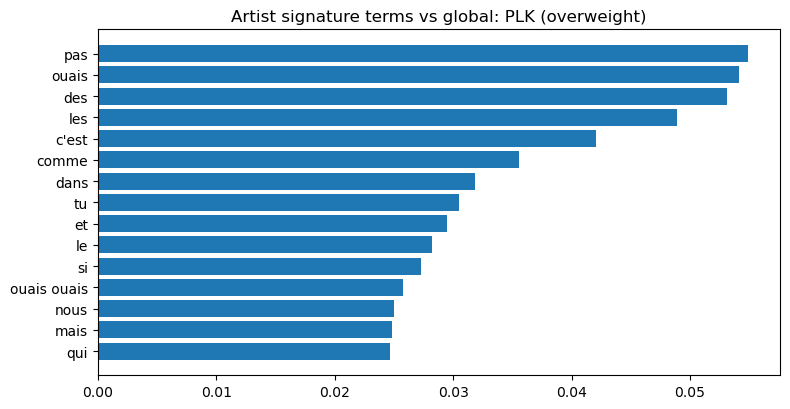

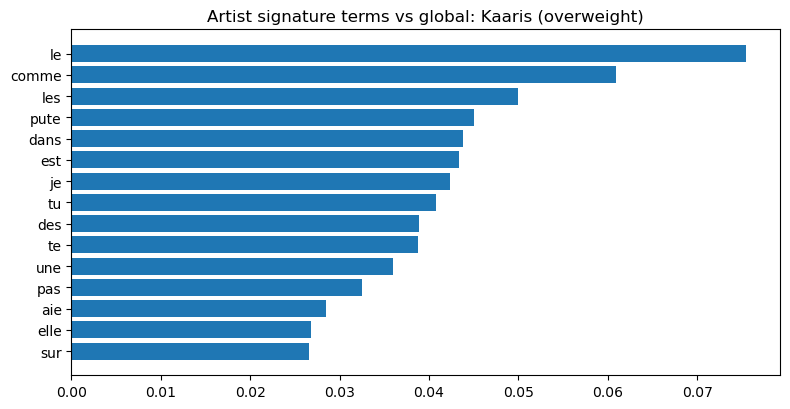

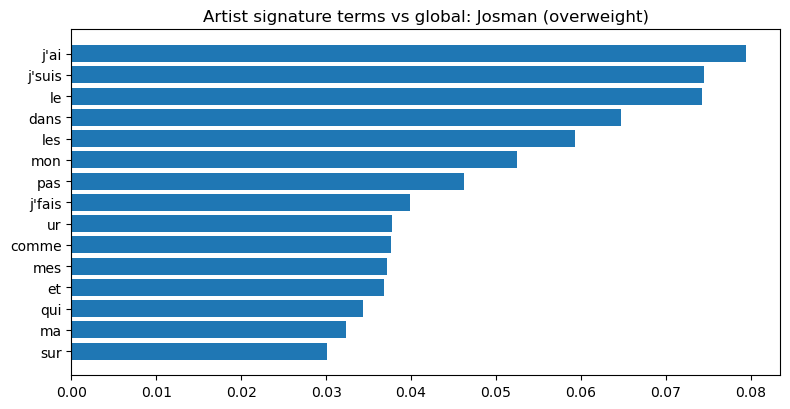

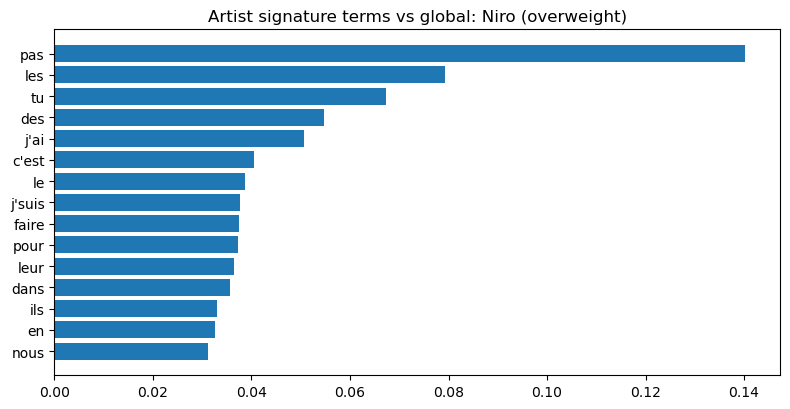

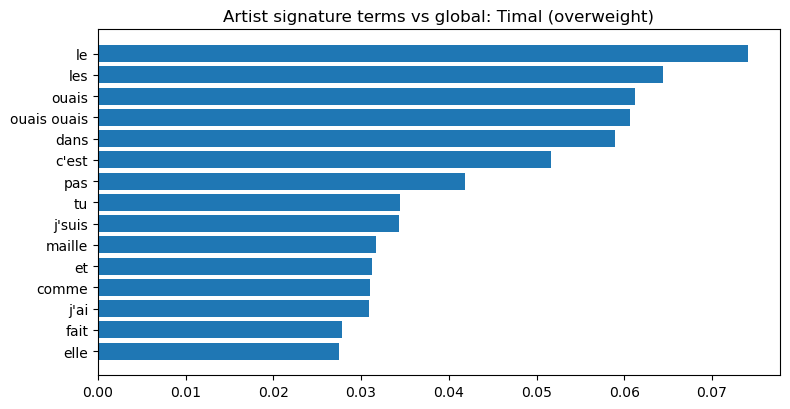

Artist TF-IDF signature table (sample)


,artist,term,artist_mean_tfidf,global_mean_tfidf,artist_minus_global,direction
0,Jul,pas,0.132275,0.053536,0.078739,artist_overweight
1,Jul,tu,0.091697,0.032674,0.059023,artist_overweight
2,Jul,des,0.075308,0.030975,0.044333,artist_overweight
3,Jul,le,0.093260,0.048955,0.044305,artist_overweight
4,Jul,les,0.092064,0.048082,0.043983,artist_overweight
5,Jul,ils,0.054376,0.012673,0.041704,artist_overweight
6,Jul,je,0.073197,0.032080,0.041117,artist_overweight
7,Jul,moi,0.059311,0.020374,0.038937,artist_overweight
8,Jul,et,0.065858,0.030862,0.034996,artist_overweight
9,Jul,fais,0.043918,0.009456,0.034462,artist_overweight


In [32]:
# This cell summarizes global TF-IDF term importance across all lyrics.
if ARTIST_COL is None or ARTIST_COL not in work.columns:
    print("No artist column detected; skip artist-level TF-IDF comparison.")
else:
    artist_df = work.loc[texts_all.index].copy()  # 对齐到 texts_all
    artist_counts = artist_df[ARTIST_COL].astype(str).value_counts(dropna=False)

    MIN_SONGS_PER_ARTIST = 20   # 可调：样本太少会不稳定
    MAX_ARTISTS_TO_SHOW = 12    # 可调：展示前 N 个样本最多的 artist

    eligible_artists = artist_counts[artist_counts >= MIN_SONGS_PER_ARTIST].index.tolist()
    top_artists = eligible_artists[:MAX_ARTISTS_TO_SHOW]

    print(f"Eligible artists (n>={MIN_SONGS_PER_ARTIST}): {len(eligible_artists)}")
    print("Showing:", top_artists)

    artist_signature_tables = []

    for artist in top_artists:
        m_artist = tfidf_mean_by_group(X_global, artist_df[ARTIST_COL].astype(str), str(artist))
        if m_artist is None:
            continue

        diff = m_artist - mean_tfidf_global
        sig_df = pd.DataFrame({
            "artist": artist,
            "term": terms_global,
            "artist_mean_tfidf": m_artist,
            "global_mean_tfidf": mean_tfidf_global,
            "artist_minus_global": diff
        })

        top_pos = sig_df.sort_values("artist_minus_global", ascending=False).head(15).copy()
        top_neg = sig_df.sort_values("artist_minus_global", ascending=True).head(15).copy()
        top_pos["direction"] = "artist_overweight"
        top_neg["direction"] = "artist_underweight"
        artist_signature_tables.append(pd.concat([top_pos, top_neg], axis=0))

        plot_barh_terms(
            top_pos[["term", "artist_minus_global"]].rename(columns={"artist_minus_global":"score"}),
            value_col="score",
            title=f"Artist signature terms vs global: {artist} (overweight)"
        )

    if artist_signature_tables:
        artist_signature_df = pd.concat(artist_signature_tables, ignore_index=True)
        safe_display(artist_signature_df, n=30, title="Artist TF-IDF signature table (sample)")
    else:
        print("No artist signature tables generated.")

In [33]:
# This cell filters valid rows and cleans raw lyrics text.
cv = CountVectorizer(
    max_features=5000,
    ngram_range=(1,1),        # LDA先用unigram更稳
    min_df=5,
    max_df=0.8,
    stop_words=list(STOPWORDS),
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b"
)

texts_for_topic = work["lyrics_clean"].fillna("").astype(str)
valid_mask_topic = texts_for_topic.str.len() > 0
topic_df = work.loc[valid_mask_topic].copy()
X_count = cv.fit_transform(texts_for_topic[valid_mask_topic])
terms_count = np.array(cv.get_feature_names_out())

N_TOPICS = 8   # 可调：6~12常见
lda = LatentDirichletAllocation(
    n_components=N_TOPICS,
    random_state=42,
    learning_method="batch",
    max_iter=20
)
doc_topic = lda.fit_transform(X_count)  # shape: n_docs x n_topics

for k in range(N_TOPICS):
    topic_df[f"topic_{k}"] = doc_topic[:, k]
topic_df["dominant_topic"] = doc_topic.argmax(axis=1)

topic_keywords = []
for k, comp in enumerate(lda.components_):
    idx = np.argsort(-comp)[:12]
    topic_keywords.append({
        "topic": k,
        "top_terms": ", ".join(terms_count[idx])
    })
topic_keywords_df = pd.DataFrame(topic_keywords)
safe_display(topic_keywords_df, n=20, title="LDA topics (top terms)")

LDA topics (top terms)


,topic,top_terms
0,0,"pas, les, c'est, le, des, dans, j'ai, j'suis, ..."
1,1,"ich, und, die, du, der, nicht, ist, wie, auf, ..."
2,2,"i'm, like, don't, got, know, just, love, it's,..."
3,3,"le, dans, les, je, comme, et, est, en, j'suis,..."
4,4,"pas, je, tu, que, moi, c'est, et, j'ai, le, ma..."
5,5,"da, tu, bye, ke, ye, se, ni, hai, te, tou, pa, hi"
6,6,"baby, po, bad, ti, bra, mm, gib, hmm, ma, bam,..."
7,7,"ja, gang, bang, money, bitch, dicka, big, ha, ..."


Artist-level average topic shares (LDA mixture)


,artist_name,topic_0,topic_1,topic_2,topic_3,topic_4,topic_5,topic_6,topic_7,n_songs
0,Djadja & Dinaz,0.683794,0.000891,0.000565,0.031044,0.278172,0.002521,0.001644,0.001370,113
1,Josman,0.405285,0.000590,0.013068,0.382610,0.180589,0.004442,0.009561,0.003856,69
2,Jul,0.552692,0.000809,0.000809,0.074040,0.354891,0.010847,0.004619,0.001294,317
3,Kaaris,0.508572,0.000778,0.001778,0.317888,0.146551,0.011712,0.006113,0.006609,70
4,Luciano,0.000578,0.774208,0.053233,0.001175,0.000979,0.001394,0.113999,0.054435,74
5,Morgan Wallen,0.001111,0.001111,0.986696,0.001111,0.001579,0.002096,0.004198,0.002099,97
6,Naps,0.634437,0.000555,0.004477,0.195041,0.134848,0.009336,0.014904,0.006400,83
7,Niro,0.726866,0.000806,0.001297,0.046987,0.208268,0.011555,0.001449,0.002772,68
8,PLK,0.641365,0.000468,0.002811,0.100701,0.243773,0.001632,0.001640,0.007609,74
9,RK,0.595130,0.000472,0.000666,0.107350,0.285077,0.003734,0.003019,0.004552,82


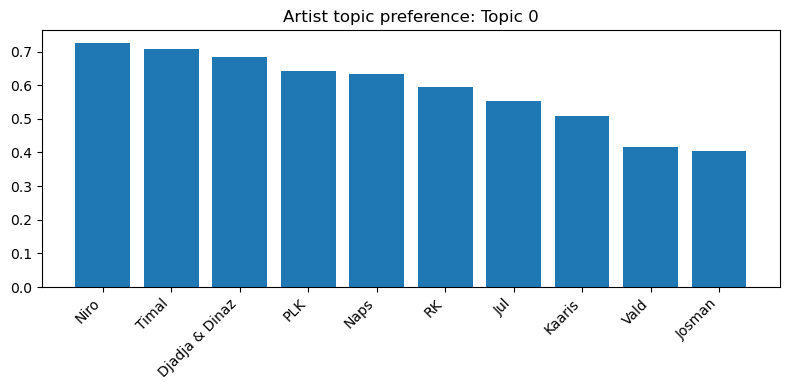

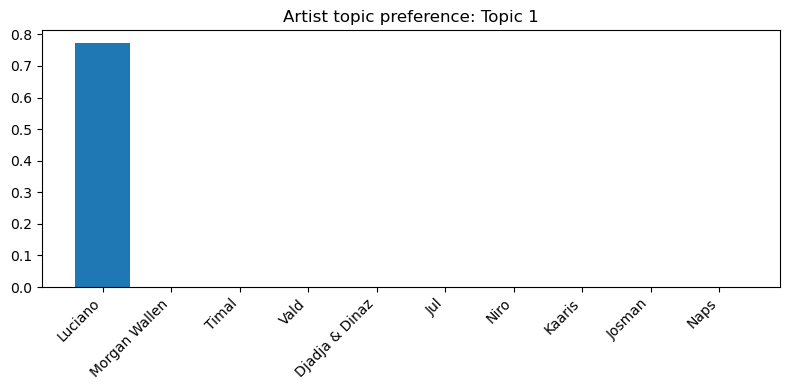

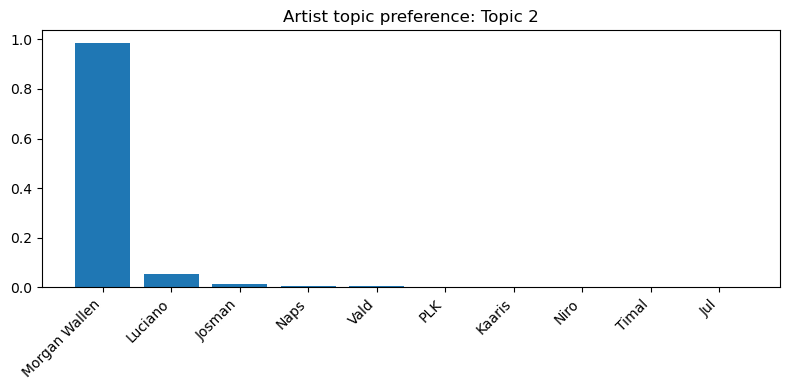

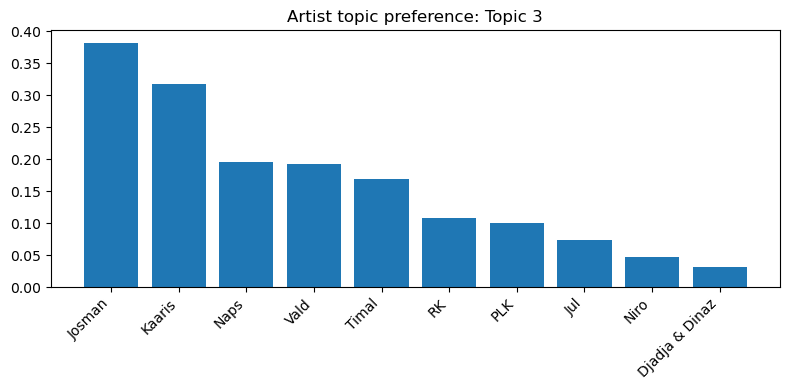

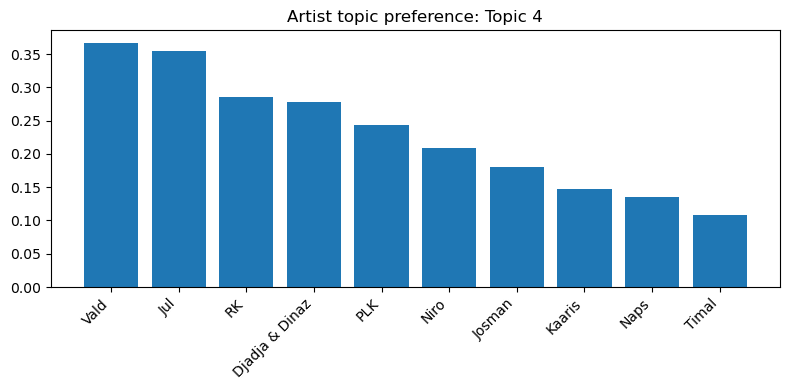

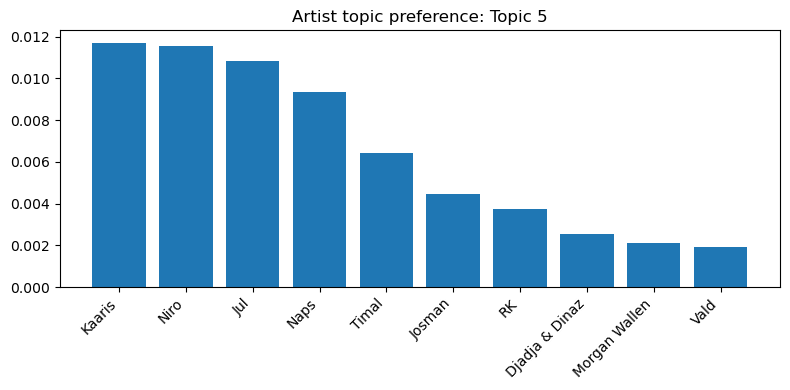

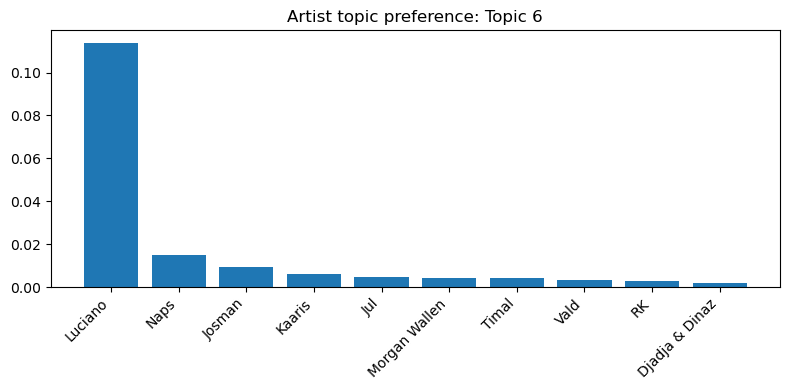

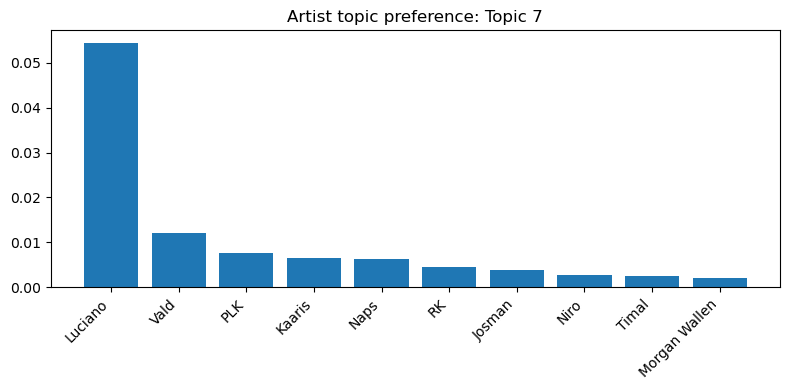

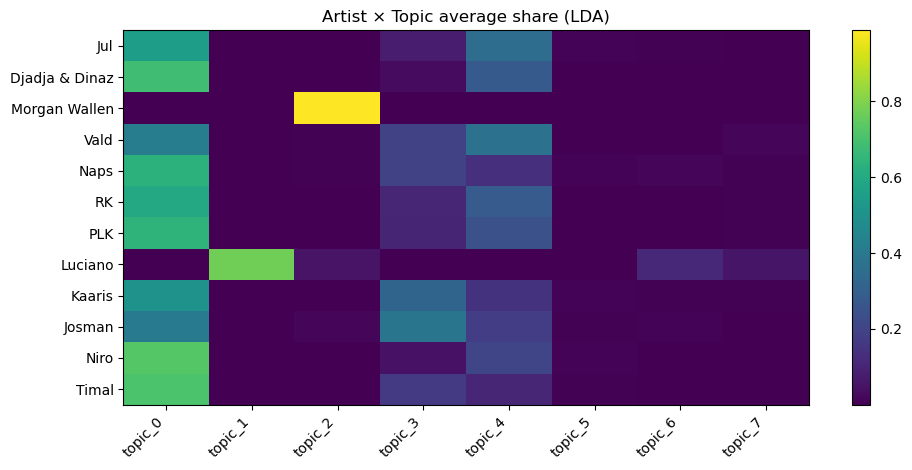

In [34]:
# This cell fits an LDA topic model and computes topic mixtures for songs.
if ARTIST_COL is None or ARTIST_COL not in topic_df.columns:
    print("No artist column detected; skip artist-topic trend.")
else:
    artist_counts_topic = topic_df[ARTIST_COL].astype(str).value_counts()
    MIN_SONGS_ARTIST_TOPIC = 20
    artists_topic = artist_counts_topic[artist_counts_topic >= MIN_SONGS_ARTIST_TOPIC].index.tolist()[:12]

    if len(artists_topic) == 0:
        print("No artists with enough songs for artist-topic trend.")
    else:
        tmp = topic_df[topic_df[ARTIST_COL].astype(str).isin(artists_topic)].copy()
        topic_cols = [f"topic_{k}" for k in range(N_TOPICS)]

        artist_topic_share = (
            tmp.groupby(ARTIST_COL)[topic_cols]
            .mean()
            .reset_index()
        )

        artist_n = tmp.groupby(ARTIST_COL).size().rename("n_songs").reset_index()
        artist_topic_share = artist_topic_share.merge(artist_n, on=ARTIST_COL, how="left")

        safe_display(artist_topic_share, n=20, title="Artist-level average topic shares (LDA mixture)")

        for k in range(N_TOPICS):
            col = f"topic_{k}"
            show = artist_topic_share[[ARTIST_COL, col, "n_songs"]].sort_values(col, ascending=False).head(10)
            plt.figure(figsize=(8,4))
            plt.bar(show[ARTIST_COL].astype(str), show[col])
            plt.title(f"Artist topic preference: Topic {k}")
            plt.xticks(rotation=45, ha="right")
            plt.tight_layout()
            plt.show()

        artists_order = artist_topic_share.sort_values("n_songs", ascending=False)[ARTIST_COL].astype(str).tolist()
        heat = (
            artist_topic_share.set_index(ARTIST_COL)
            .loc[artists_order, topic_cols]
        )
        plt.figure(figsize=(10, max(4, 0.4*len(heat))))
        plt.imshow(heat.values, aspect="auto")
        plt.colorbar()
        plt.yticks(np.arange(len(heat.index)), heat.index.astype(str))
        plt.xticks(np.arange(len(topic_cols)), topic_cols, rotation=45, ha="right")
        plt.title("Artist × Topic average share (LDA)")
        plt.tight_layout()
        plt.show()

tfidf_cluster
0    2232
1     646
2     858
3    1295
4    1245
5     839
6     994
7    2184
Name: count, dtype: int64


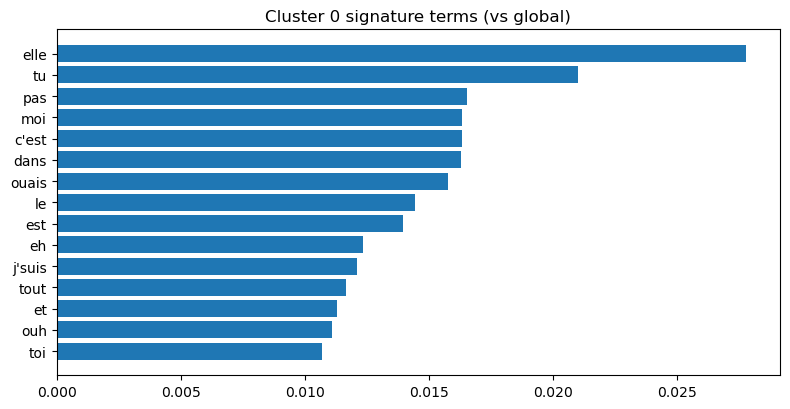

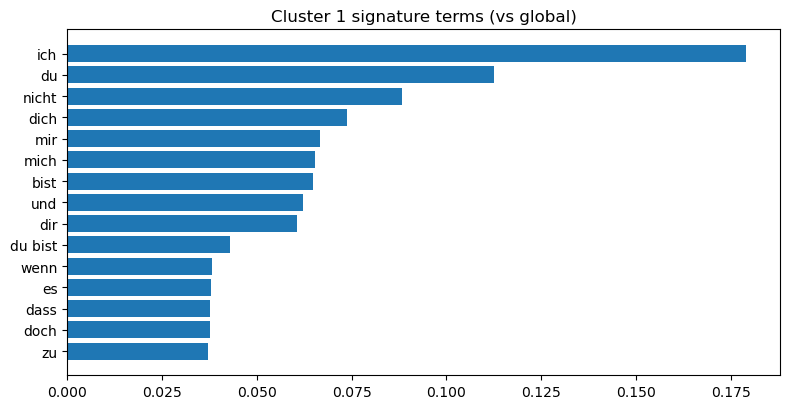

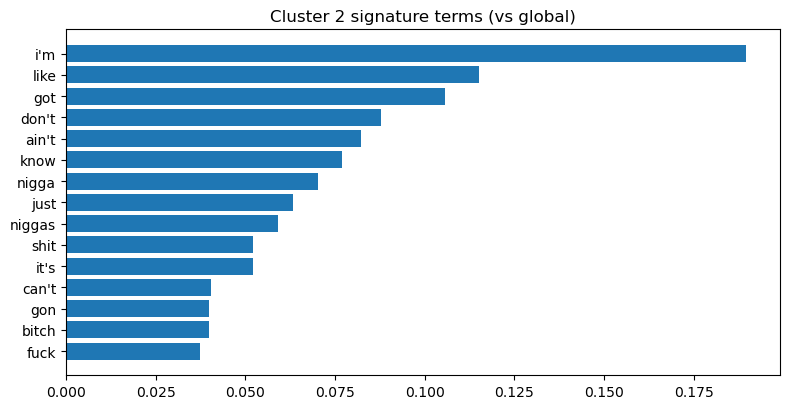

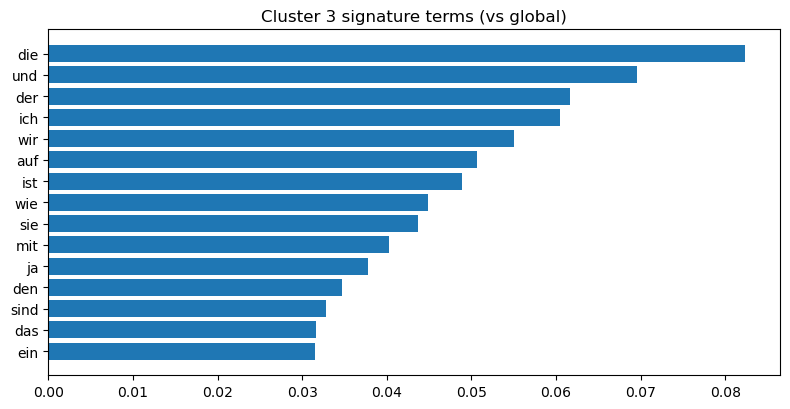

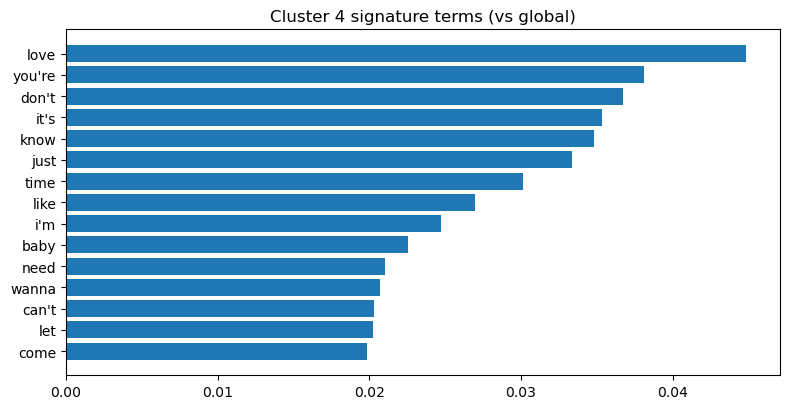

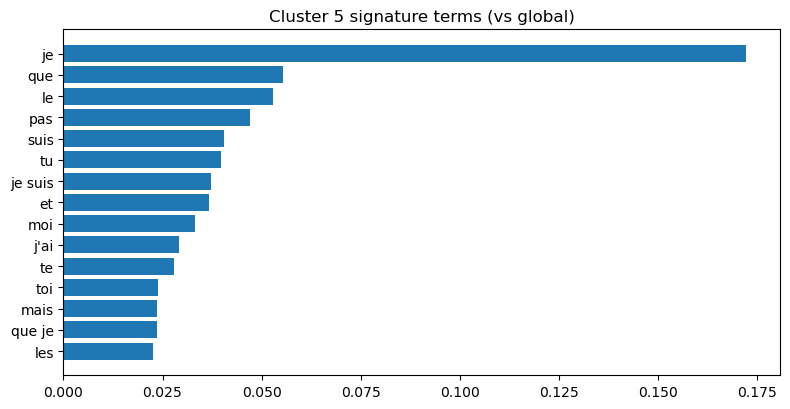

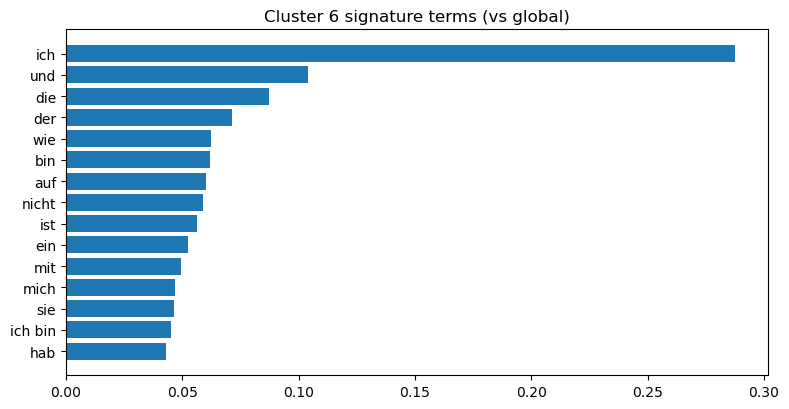

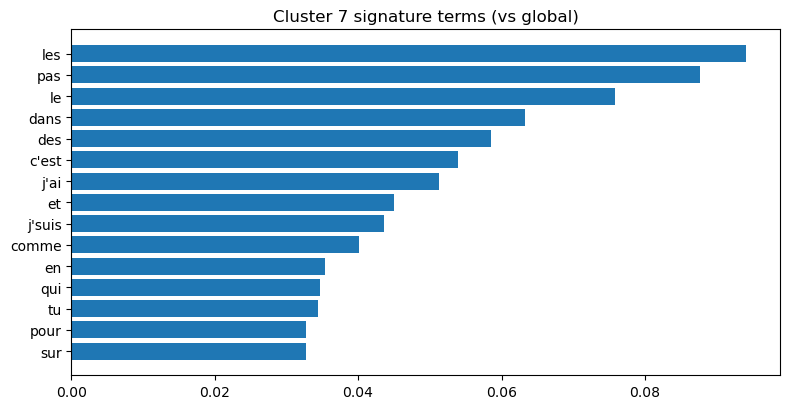

Cluster signature terms (sample)


,term,score,cluster
0,elle,0.027768,0
1,tu,0.021015,0
2,pas,0.016527,0
3,moi,0.016353,0
4,c'est,0.016329,0
5,dans,0.016300,0
6,ouais,0.015782,0
7,le,0.014439,0
8,est,0.013977,0
9,eh,0.012369,0


Artist-level cluster composition (row-normalized)


tfidf_cluster,artist_name,0,1,2,3,4,5,6,7
0,13 Block,0.452381,0.000000,0.000000,0.000000,0.000000,0.071429,0.000000,0.476190
1,4Keus,0.480000,0.000000,0.000000,0.000000,0.000000,0.080000,0.000000,0.440000
2,AYLIVA,0.000000,0.850000,0.000000,0.050000,0.100000,0.000000,0.000000,0.000000
3,Alonzo,0.486486,0.000000,0.000000,0.000000,0.000000,0.270270,0.000000,0.243243
4,Ang猫le,0.666667,0.000000,0.000000,0.000000,0.074074,0.259259,0.000000,0.000000
5,Apache 207,0.000000,0.361111,0.000000,0.194444,0.000000,0.000000,0.444444,0.000000
6,Aya Nakamura,0.833333,0.000000,0.000000,0.000000,0.000000,0.166667,0.000000,0.000000
7,Bigflo & Oli,0.324324,0.000000,0.000000,0.000000,0.000000,0.297297,0.000000,0.378378
8,Bonez MC,0.000000,0.375000,0.000000,0.375000,0.000000,0.000000,0.250000,0.000000
9,Booba,0.153846,0.000000,0.000000,0.000000,0.000000,0.230769,0.000000,0.615385


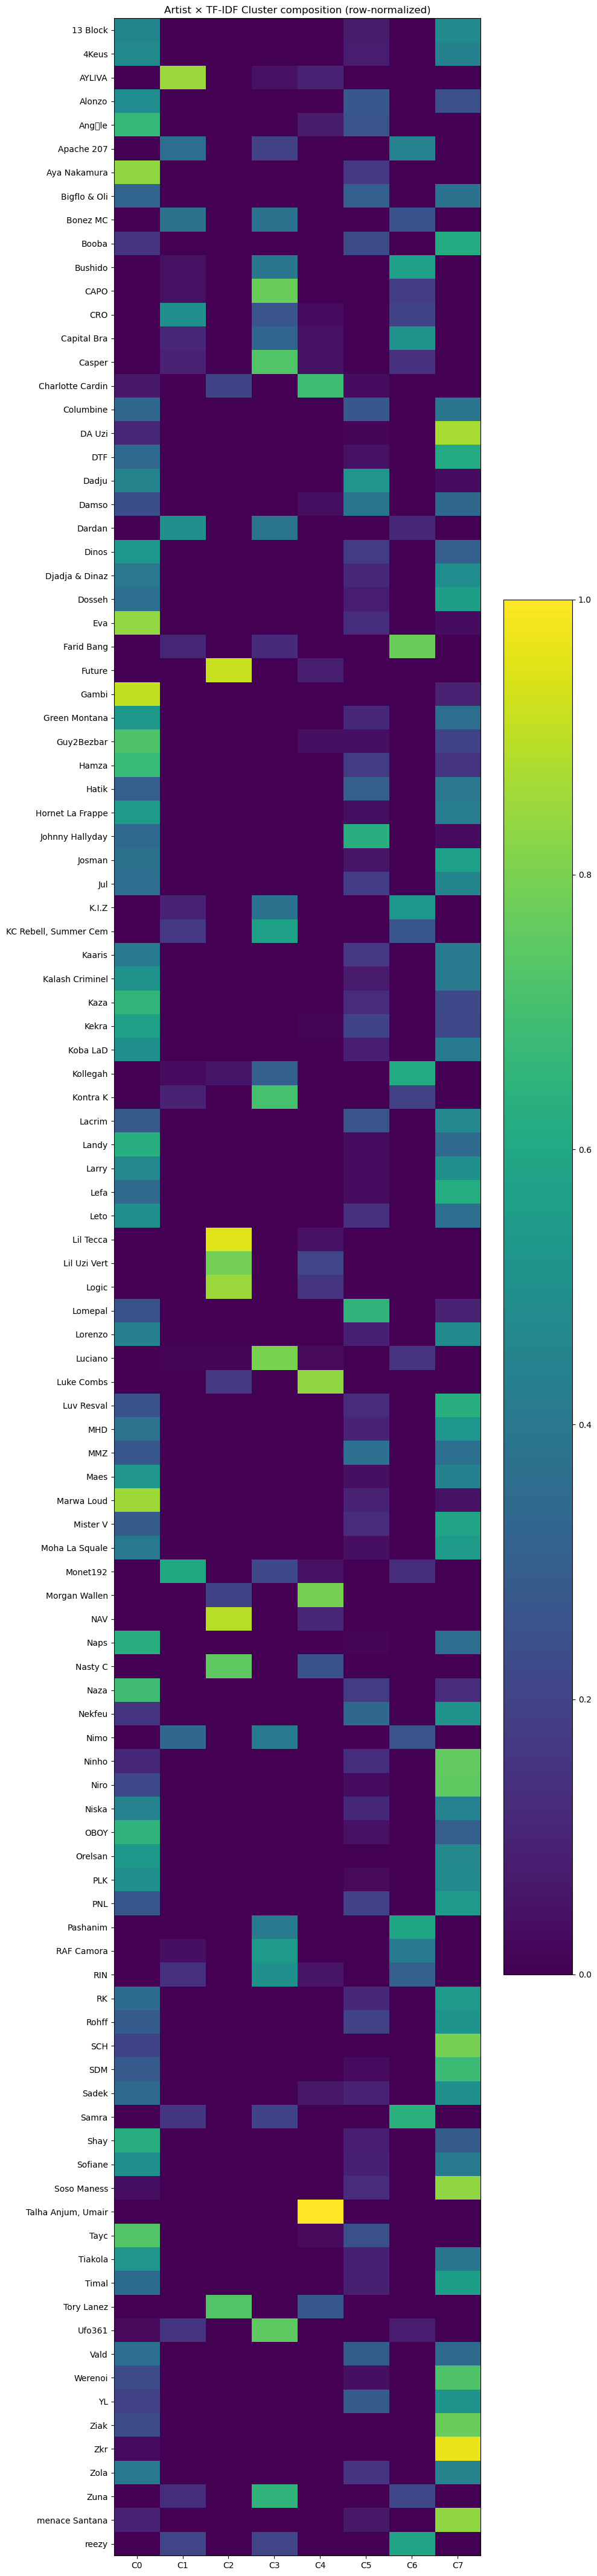

In [35]:
# This cell summarizes global TF-IDF term importance across all lyrics.
cluster_df = work.loc[texts_all.index].copy()

SVD_DIM = 50
svd = TruncatedSVD(n_components=SVD_DIM, random_state=42)
X_svd = svd.fit_transform(X_global)

N_CLUSTERS = 8
km = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=10)
cluster_labels = km.fit_predict(X_svd)
cluster_df["tfidf_cluster"] = cluster_labels

print(cluster_df["tfidf_cluster"].value_counts().sort_index())

cluster_term_tables = []
for cl in sorted(cluster_df["tfidf_cluster"].unique()):
    idx = np.where(cluster_df["tfidf_cluster"].values == cl)[0]
    m_cl = np.asarray(X_global[idx].mean(axis=0)).ravel()
    m_diff = m_cl - mean_tfidf_global

    top_terms = pd.DataFrame({"term": terms_global, "score": m_diff}).sort_values("score", ascending=False).head(15)
    top_terms["cluster"] = cl
    cluster_term_tables.append(top_terms)

    plot_barh_terms(
        top_terms[["term","score"]],
        value_col="score",
        title=f"Cluster {cl} signature terms (vs global)"
    )

cluster_terms_df = pd.concat(cluster_term_tables, ignore_index=True)
safe_display(cluster_terms_df, n=40, title="Cluster signature terms (sample)")

if ARTIST_COL is not None and ARTIST_COL in cluster_df.columns:
    ctab_artist_cluster = pd.crosstab(
        cluster_df[ARTIST_COL].astype(str),
        cluster_df["tfidf_cluster"],
        normalize="index"  # 每个artist内部的cluster占比
    )
    artist_counts_cluster = cluster_df[ARTIST_COL].astype(str).value_counts()
    keep_artists = artist_counts_cluster[artist_counts_cluster >= 20].index
    ctab_artist_cluster = ctab_artist_cluster.loc[ctab_artist_cluster.index.isin(keep_artists)]

    safe_display(ctab_artist_cluster.reset_index(), n=20, title="Artist-level cluster composition (row-normalized)")

    if len(ctab_artist_cluster) > 0:
        plt.figure(figsize=(10, max(4, 0.4*len(ctab_artist_cluster))))
        plt.imshow(ctab_artist_cluster.values, aspect="auto")
        plt.colorbar()
        plt.yticks(np.arange(len(ctab_artist_cluster.index)), ctab_artist_cluster.index.astype(str))
        plt.xticks(np.arange(len(ctab_artist_cluster.columns)), [f"C{c}" for c in ctab_artist_cluster.columns])
        plt.title("Artist × TF-IDF Cluster composition (row-normalized)")
        plt.tight_layout()
        plt.show()
else:
    print("No artist column detected; skip artist-cluster composition.")

In [11]:
# This cell filters valid rows and cleans raw lyrics text.
pointwise = work.copy()

if "target_bucket" in pointwise.columns and pointwise["target_bucket"].isin(["Top20","Avg"]).sum() > 50:
    sub = pointwise[pointwise["target_bucket"].isin(["Top20","Avg"])].copy().reset_index(drop=True)
    vec = TfidfVectorizer(max_features=3000, ngram_range=(1,2), min_df=5, max_df=0.8,
                          stop_words=list(STOPWORDS), token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b")
    X = vec.fit_transform(sub["lyrics_clean"])
    terms_pw = np.array(vec.get_feature_names_out())

    m_top = np.asarray(X[sub["target_bucket"].eq("Top20")].mean(axis=0)).ravel()
    m_avg = np.asarray(X[sub["target_bucket"].eq("Avg")].mean(axis=0)).ravel()
    direction = m_top - m_avg
    score = np.asarray(X @ direction.reshape(-1,1)).ravel()
    sub["text_signature_score"] = score

    sub["text_sig_pct"] = sub["text_signature_score"].rank(pct=True)
    if "_rank" in sub.columns and sub["_rank"].notna().sum() > 10:
        sub["rank_pct"] = (-sub["_rank"]).rank(pct=True)
        sub["rank_pct_diff_minus_text"] = sub["rank_pct"] - sub["text_sig_pct"]

    reg_features = [c for c in ["n_tokens","lexical_diversity_ttr","repetition_ratio_lines","tb_polarity","pron_1_rate","pron_2_rate"] if c in sub.columns]
    if TARGET_COL is not None and len(reg_features) >= 2 and sub[TARGET_COL].notna().sum() > 50:
        tmp = sub[reg_features + [TARGET_COL]].dropna()
        Xr = sm.add_constant(tmp[reg_features])
        yr = tmp[TARGET_COL]
        model = sm.OLS(yr, Xr).fit()
        resid = model.resid
        z = (resid - resid.mean()) / (resid.std(ddof=0) + 1e-9)
        sub.loc[tmp.index, "baseline_resid_z"] = z
        print(model.summary().tables[1])

    display_cols = [c for c in [TRACK_COL, ARTIST_COL, "text_signature_score", "text_sig_pct", "rank_pct", "rank_pct_diff_minus_text", "baseline_resid_z", TARGET_COL] if c is not None and c in sub.columns]
    display(sub.sort_values("text_signature_score", ascending=False)[display_cols].head(20))
    if "rank_pct_diff_minus_text" in sub.columns:
        display(sub.sort_values("rank_pct_diff_minus_text", ascending=False)[display_cols].head(20))
        display(sub.sort_values("rank_pct_diff_minus_text", ascending=True)[display_cols].head(20))
else:
    print("Insufficient target buckets for pointwise TF-IDF signature diagnostics.")

Insufficient target buckets for pointwise TF-IDF signature diagnostics.


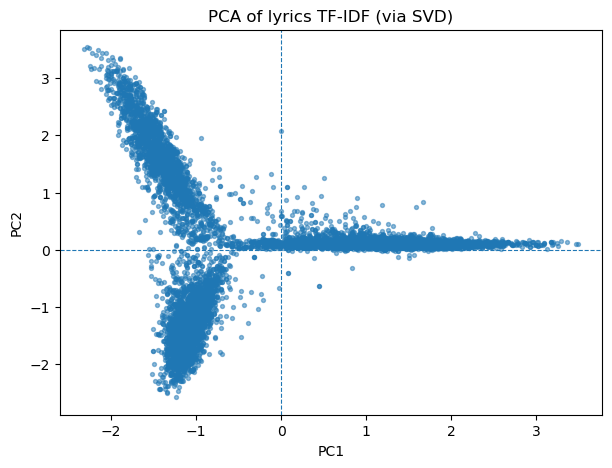

Explained variance ratio (PCA on SVD features): [0.01650673 0.01176876]


In [14]:
# This cell filters valid rows and cleans raw lyrics text.
vec_pca = TfidfVectorizer(
    max_features=5000, ngram_range=(1,2), min_df=5, max_df=0.8,
    stop_words=list(STOPWORDS), token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z']+\b"
)
X_doc = vec_pca.fit_transform(work["lyrics_clean"])
svd = TruncatedSVD(n_components=min(100, X_doc.shape[1]-1), random_state=42)
X_svd = svd.fit_transform(X_doc)

pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(StandardScaler().fit_transform(X_svd))
work["pc1_text"] = X_2d[:,0]
work["pc2_text"] = X_2d[:,1]

plt.figure(figsize=(7,5))
if "target_bucket" in work.columns and work["target_bucket"].notna().sum() > 50:
    for g in ["Top20","Avg","Bottom20"]:
        mask = work["target_bucket"].eq(g)
        if mask.sum()==0: 
            continue
        plt.scatter(work.loc[mask,"pc1_text"], work.loc[mask,"pc2_text"], s=12, alpha=0.5, label=g)
    plt.legend()
else:
    plt.scatter(work["pc1_text"], work["pc2_text"], s=8, alpha=0.5)
plt.axhline(0, linestyle="--", linewidth=0.8)
plt.axvline(0, linestyle="--", linewidth=0.8)
plt.title("PCA of lyrics TF-IDF (via SVD)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

print("Explained variance ratio (PCA on SVD features):", pca.explained_variance_ratio_)